In [11]:
import skyfield
import numpy as np
from matplotlib import pyplot as plt
import catalogo
import os
import funciones_base
import satelite
import analisis
import datetime

In [2]:
base=os.getcwd()
catalogos=catalogo.leer_satelites(f"{base}\datos\satelites.json")
print(f"Hay {len(catalogos)} satelites en el catalogo")
momento=funciones_base.epoch_medio(catalogos)
print(f"Epoch medio de los datos:",momento)
lista_satelites=satelite.crear_satelites(catalogos,momento)
print(F"Satelites cargados:{len(lista_satelites)}")

Hay 16822 satelites en el catalogo
Epoch medio de los datos: 2026-10-27 00:56:47.794596+00:00
Satelites cargados:16822


In [3]:
contar_grupos=catalogo.contar_por_grupo(catalogos)
total=0
for nombre,cantidad in contar_grupos.items():
    total=total+cantidad
    print(f"{nombre}:{cantidad}")
porcentaje_starlink=(contar_grupos["Starlink"]*100)/total  #100% =total x%=starlink
print(f"Starlink tiene un {round(porcentaje_starlink,2)}% del total")

Otros:4844
GPS:40
Globalstar:36
Iridium:80
OneWeb:651
Starlink:10523
Qianfan:257
Kuiper:391
Starlink tiene un 62.55% del total


In [4]:
diccionario_anios=catalogo.lanzamiento_por_anio(catalogos)
maximo=0
anio_maximo=0
for anio,cantidad in diccionario_anios.items():
    if anio>=2015:
        print(f"{anio}:{cantidad}")
        if cantidad>maximo:
            maximo=cantidad
            anio_maximo=anio
print(f"El año {anio_maximo} tuvo el maximo de satelites con {maximo}")

2015:96
2016:84
2017:136
2018:193
2019:144
2020:354
2021:987
2022:1715
2023:2260
2024:2428
2025:4289
2026:3421
El año 2025 tuvo el maximo de satelites con 4289


In [5]:
diccionario_tipos=analisis.contar_por_tipo(lista_satelites)
for tipo, cantidad in diccionario_tipos.items():
    print(f"{tipo}:{cantidad}")

LEO:16013
MEO:197
GEO:589
HEO:23


In [6]:
BARILOCHE = (-76.30, -46.13, -66.30, -36.13)   # lon_min, lat_min, lon_max, lat_max ZONA DE EJEMPLO
satelites_en_zona=analisis.en_zona(lista_satelites,BARILOCHE)
satelites_en_zona=analisis.ordenar_por(satelites_en_zona,"altitud_km")

In [7]:
maximo=0
for anio,cantidad in diccionario_anios.items():
     if cantidad>maximo:
        maximo=cantidad
        anio_maximo=anio
print(f"El año con mayor cantidad de satelites es {anio_maximo} con {maximo}")

maximo_grupo=0
nombre=""
for grupo,cantidad in contar_grupos.items():
     if cantidad>maximo_grupo:
        maximo_grupo=cantidad
        nombre=grupo
print(f"El mayor grupo es {nombre} con {maximo_grupo} satelites")

maxima_orbita=0
for orbita,cantidad in diccionario_tipos.items():
     if cantidad>maximo_grupo:
        maxima_orbita=cantidad
        nombre=orbita
print(f"La orbita con mas satelites es {nombre} con {maxima_orbita}")

print(f"Hay {len(satelites_en_zona)} satelites en bariloche")
for satelite in satelites_en_zona:
    print(satelite)


El año con mayor cantidad de satelites es 2025 con 4289
El mayor grupo es Starlink con 10523 satelites
La orbita con mas satelites es LEO con 16013
Hay 0 satelites en bariloche


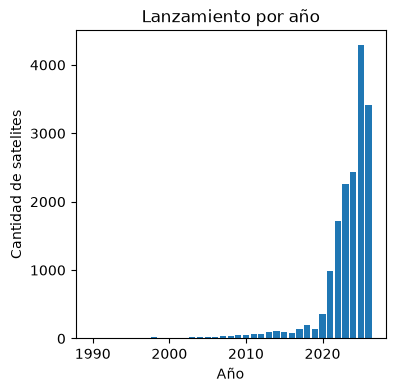

'\n\n'

In [33]:
anios=[anio for anio in diccionario_anios.keys() if anio>=1990]
cantidad=[diccionario_anios[anio] for anio in anios]
fig=plt.figure(figsize =(4,4))
plt.bar(anios,cantidad)
plt.xlabel("Año")
plt.ylabel("Cantidad de satelites")
plt.title("Lanzamiento por año")
plt.show()
'''
A partir de 2020 se ve un gran crecimiento en la cantidad de satelites.
Este crecimiento se debe al lanzamiento en masa de satelites starlink.
'''

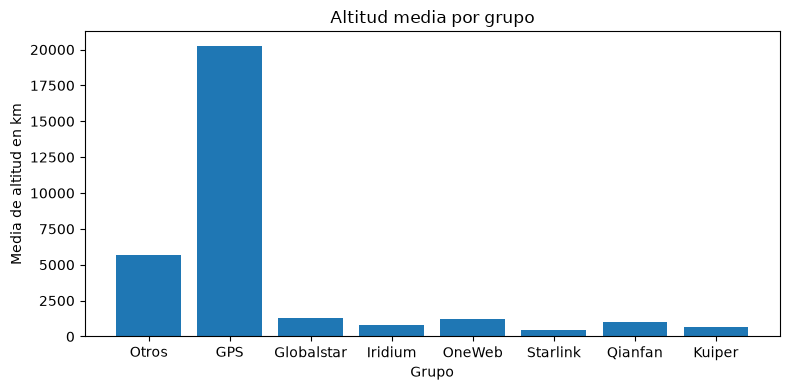

In [9]:
resumen=analisis.resumen_por_grupo(lista_satelites)
grupos=[]
medias=[]
for grupo,datos in resumen.items():
    grupos.append(grupo)
    medias.append(datos["Media"])
fig=plt.figure(figsize =(8,4))
plt.bar(grupos,medias)
plt.xlabel("Grupo")
plt.ylabel("Media de altitud en km")
plt.title("Altitud media por grupo")
plt.tight_layout()
plt.show()
'''
Los grupos en orbitas altas son los satelites del grupo GPS, seguidos de los satelites dentro
del grupo "Otros".
Los demas satelites se mantiene en altitudes inferiores a 2500
'''

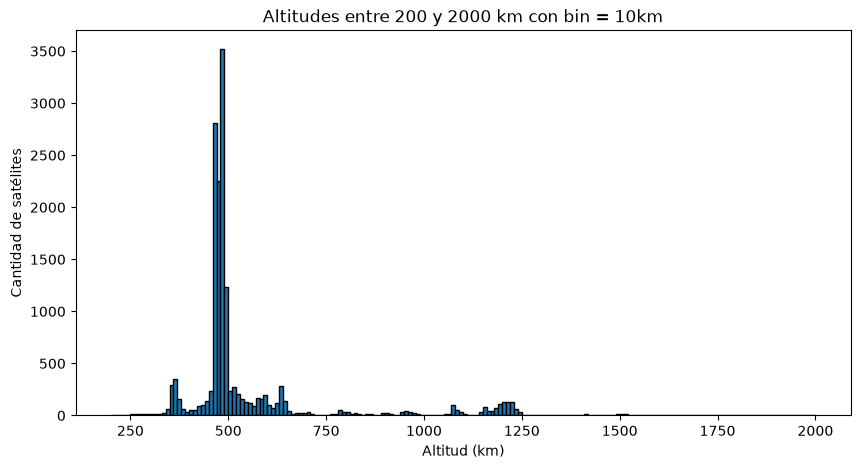

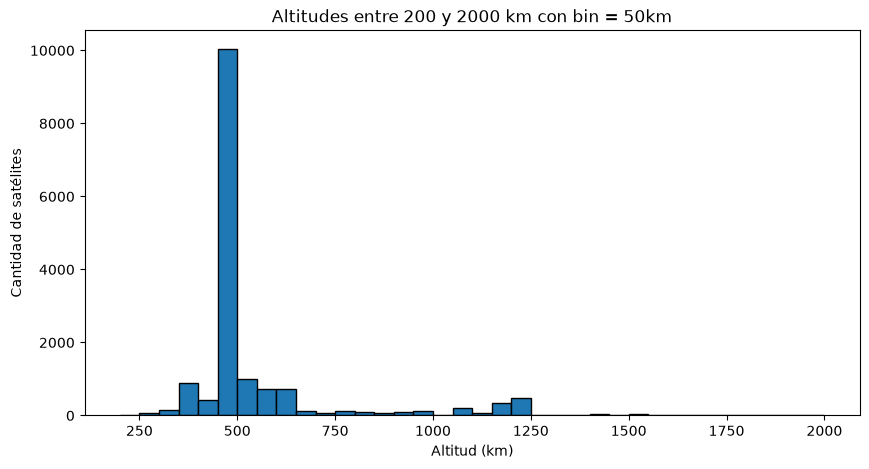

In [34]:
lista_altitudes=[satelite.altitud_km for satelite in lista_satelites if satelite.altitud_km>=200 and satelite.altitud_km<=2000]

ancho_bin=10
bins=np.arange(200,2000+ancho_bin,ancho_bin)
fig,ax=plt.subplots(figsize=(10,5))
ax.hist(lista_altitudes,bins=bins,edgecolor="black")
ax.set_title("Altitudes entre 200 y 2000 km con bin = 10km")
ax.set_xlabel("Altitud (km)")
ax.set_ylabel("Cantidad de satélites")
plt.show()
'''
Los satelites en general se encuentran a orbitas bajas.
Al usar 10 bin se puede ver con mayor precision ya que usa mas picos.
Al usar 50 bin se aprecia mejor la diferencia de altitudes pero no es tan detallado.
'''

lista_altitudes=[satelite.altitud_km for satelite in lista_satelites if satelite.altitud_km>=200 and satelite.altitud_km<=2000]

ancho_bin=50
bins=np.arange(200,2000+ancho_bin,ancho_bin)
fig,ax=plt.subplots(figsize=(10,5))
ax.hist(lista_altitudes,bins=bins,edgecolor="black")
ax.set_title("Altitudes entre 200 y 2000 km con bin = 50km")
ax.set_xlabel("Altitud (km)")
ax.set_ylabel("Cantidad de satélites")
plt.show()


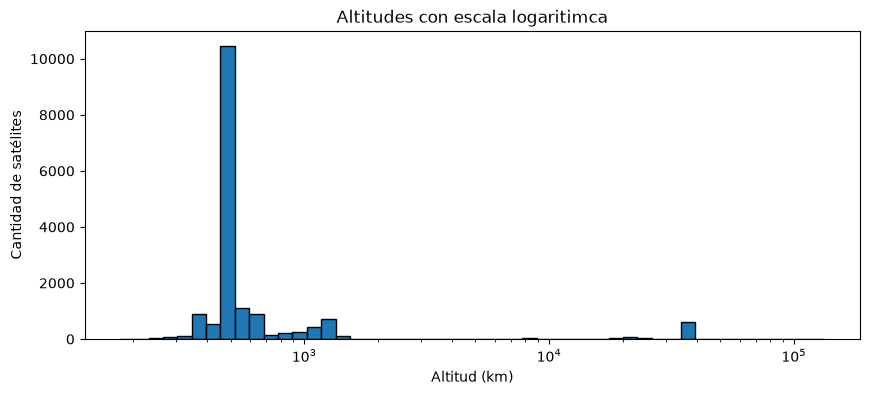

'\n\n'

In [36]:
lista_altitudes=[satelite.altitud_km for satelite in lista_satelites if satelite.altitud_km>=100]
bins=np.logspace(np.log10(min(lista_altitudes)),np.log10(max(lista_altitudes)),50)

fig,ax=plt.subplots(figsize=(10,4))
ax.hist(lista_altitudes,bins=bins,edgecolor="black")

ax.set_xscale("log")
ax.set_title("Altitudes con escala logaritimca")
ax.set_xlabel("Altitud (km)")
ax.set_ylabel("Cantidad de satélites")
plt.show()

'''
Los picos predominan antes de altitud 10**3 es decir 1000km
Por lo tanto el grupo LEO(altitud<2000km) es el que predomina
'''

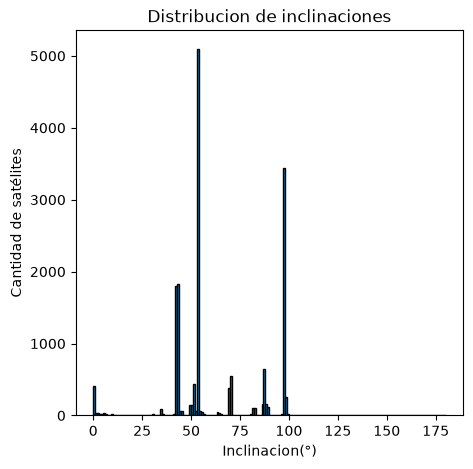

In [27]:
lista_inclinaciones=[registro["INCLINATION"] for registro in catalogos]
bins=np.arange(0,181,1)#De 0° a 180°
fig,ax=plt.subplots(figsize=(5,5))
ax.hist(lista_inclinaciones,bins=bins,edgecolor="black")

ax.set_title("Distribucion de inclinaciones")
ax.set_xlabel("Inclinacion(°)")
ax.set_ylabel("Cantidad de satélites")
plt.show()




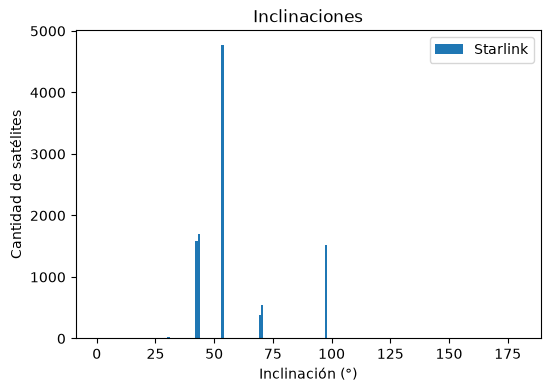

In [68]:
starlink = [
    registro["INCLINATION"]
    for registro in catalogos
    if catalogo.grupo(registro["OBJECT_NAME"]) == "Starlink"
]
bins = np.arange(0, 181, 1)
fig, ax = plt.subplots(figsize=(6,4))
ax.hist(starlink, bins=bins,label="Starlink")
ax.set_title("Inclinaciones")
ax.set_xlabel("Inclinación (°)")
ax.set_ylabel("Cantidad de satélites")
ax.legend()
plt.show()


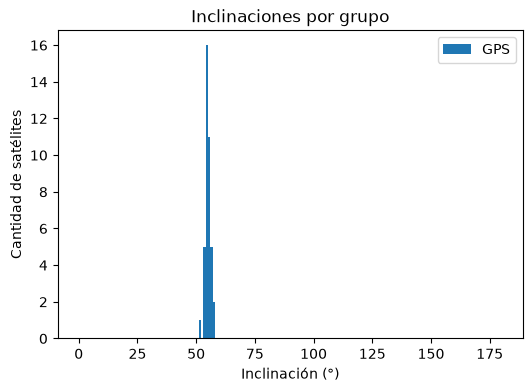

In [69]:
gps = [
    registro["INCLINATION"]
    for registro in catalogos
    if catalogo.grupo(registro["OBJECT_NAME"]) == "GPS"
]
bins = np.arange(0, 181, 1)
fig, ax = plt.subplots(figsize=(6,4))
ax.hist(gps, bins=bins,label="GPS")
ax.set_title("Inclinaciones por grupo")
ax.set_xlabel("Inclinación (°)")
ax.set_ylabel("Cantidad de satélites")
ax.legend()
plt.show()


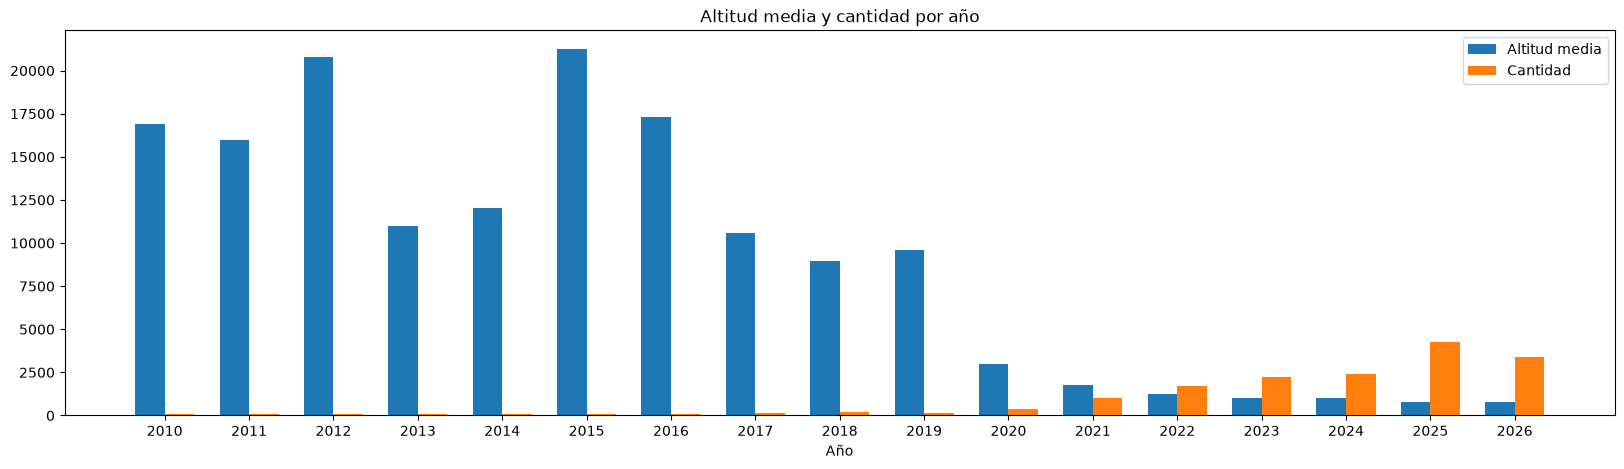

In [15]:
##TEMA LIBRE: Altitudes o cantidad a lo largo de los años
def resumen_por_anio(satelites:list) -> dict:
    """
    Esta funcion crea un diccionario con los años como clave
    y sus alittudes en una lista como valor.
    Luego usando ese diccionario creamos otro diccionario que 
    tiene los ÑOA como clave y un diccionario con datos de las
    altitudes(cantidad,minima,maxima,media).
    """
    diccionario={}
    ##Creamos diccionario con lista de altitudes para luego trabjar con ellas.
    for satelite in satelites:
        anio=satelite.anio
        altitud=satelite.altitud_km
        if anio not in diccionario and anio>=2010:
            diccionario[anio]=[]
        if anio>=2010:
            diccionario[anio].append(altitud)
    resumen = {}
    ##Trabajamos con los datos guardados
    for anio,altitudes in diccionario.items():
        resumen[anio]={
            "Cantidad":len(altitudes),
            "Minima":min(altitudes),
            "Maxima":max(altitudes),
            "Media":sum(altitudes)/len(altitudes)
        }
    return resumen  

resumen_anios=resumen_por_anio(lista_satelites)
anios=[]
medias=[]
cantidad=[]
for anio,datos in resumen_anios.items():
    anios.append(anio)
    medias.append(datos["Media"])
    cantidad.append(diccionario_anios[anio])
x_pos=list(range(len(anios)))
ancho=0.35
x_izq = [p - ancho/2 for p in x_pos]
x_der = [p + ancho/2 for p in x_pos]

fig, ax = plt.subplots(figsize=(20,5))
ax.bar(x_izq, medias, width=ancho, label="Altitud media")
ax.bar(x_der, cantidad, width=ancho, label="Cantidad")
ax.set_xticks(x_pos)
ax.set_xticklabels(anios)
ax.set_xlabel("Año")
ax.set_title("Altitud media y cantidad por año")
ax.legend()
plt.show()
    

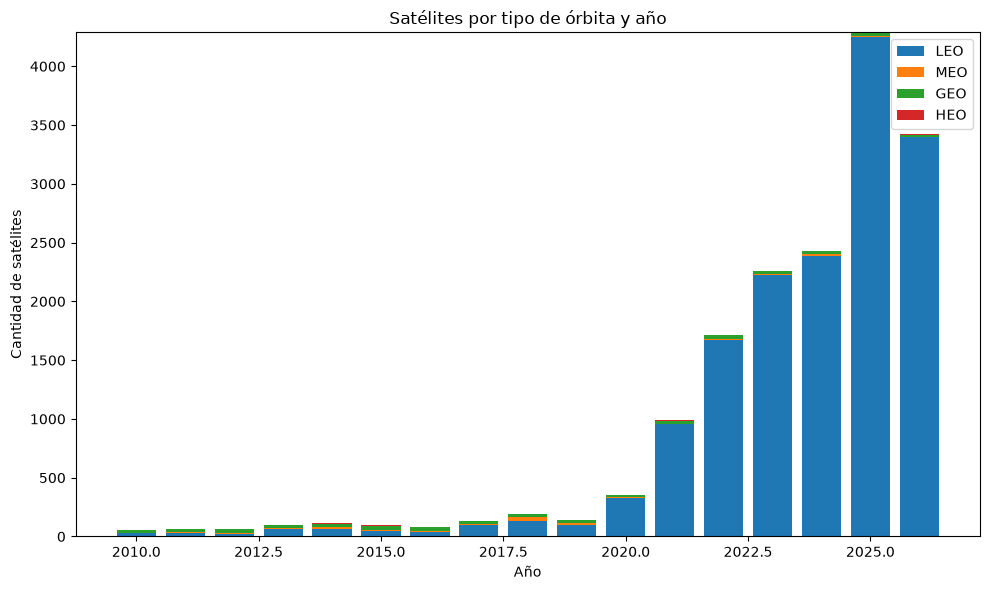

In [28]:
def orbita_por_anio(satelites):
    datos={}

    for satelite in satelites:
        anio=satelite.anio
        if anio>=2010:
            tipo=satelite.tipo_orbita()
            if anio not in datos:
                datos[anio] ={
                    "LEO":0,
                    "MEO":0,
                    "GEO":0,
                    "HEO":0  
                    }
            datos[anio][tipo]+=1
    return datos

datos=orbita_por_anio(lista_satelites)
anios = list(datos.keys())
leo = [datos[i]["LEO"] for i in anios]
meo = [datos[i]["MEO"] for i in anios]
geo = [datos[i]["GEO"] for i in anios]
heo = [datos[i]["HEO"] for i in anios]

plt.figure(figsize=(10, 6))

plt.bar(anios, leo, label="LEO")
plt.bar(anios, meo, bottom=leo, label="MEO")

bottom_geo = [
    leo[i] + meo[i]
    for i in range(len(anios))
]
plt.bar(anios, geo, bottom=bottom_geo, label="GEO")

bottom_heo = [
    leo[i] + meo[i] + geo[i]
    for i in range(len(anios))
]
plt.bar(anios, heo, bottom=bottom_heo, label="HEO")

plt.xlabel("Año")
plt.ylabel("Cantidad de satelites")
plt.title("Satelites por tipo de orbita y año")
plt.legend()

plt.tight_layout()
plt.show()

<class 'str'>
